<a href="https://colab.research.google.com/github/SashaVeremchuk/ITMO-data-analysis/blob/main/2_cluster_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Дз№2 Кластерный анализ методом k-средних (k-means)
Анализ данных на Python  
ИТМО 2026   
Веремчук Александра

## Постановка задачи
**Описание данных**   
Набор данных "Леденцы" содержит оценки степени согласия респондентов с высказываниями,
отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:   
* V1: Я потребляю леденцы, чтобы освежить дыхание  
* V2: Я потребляю леденцы, чтобы чувствовать себя увереннее  
* V3: Я потребляю леденцы, чтобы освежить полость рта   
* V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту  
* V5: Я потребляю леденцы как заменитель других кондитерских изделий  
* V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого  
* V7: Леденцы помогают мне сконцентрироваться  
* V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать  
* V9: Я потребляю леденцы для того, чтобы облегчить боль в горле  
* V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа  
* V11: Я потребляю леденцы для улучшения самочувствия  

**Задача**  
1. Определить число кластеров и обосновать выбор;   
2. Выполнить кластеризацию;  
3. Предложить содержательную интерпретацию полученных групп.



## Подключение библиотек

In [14]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [6]:
# загрузка данных
df = pd.read_csv("data/lollipops.dat", sep=";")
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


In [8]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


Данные нормальные. Пропусков и выбросов нет.

## Проведение кластерного анализа методом k-means

Для начала определим число кластеров при помощи графика "каменистая осыпь". Число кластеров будет от 1 до 11 (тк 11 вопросов).

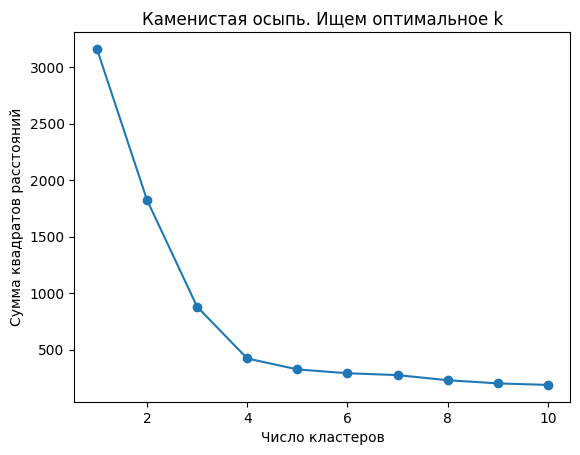

In [16]:
K = range(1, 11)
# Вычисляем значения критерия качества для разного числа кластеров
models = [KMeans(n_clusters=k, random_state=42).fit(df) for k in K]
dist = [model.inertia_ for model in models]

# Строим график каменистая осыпь
plt.plot(K, dist, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Сумма квадратов расстояний')
plt.title('Каменистая осыпь. Ищем оптимальное k')
plt.show()

Из графика видно, что оптимальное число кластеров = 4, тк это точка перегиба.   
Это так же подтвержается анализом вопросов, где можно выделить 4 группы применения леденцов:
  * Для свежести дыхания;
  * Для концентрации;
  * Как сладкое;
  * Для ослабления симптомов болезни.  